<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/models/04b_CBF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Content-based filtering (CBF) with validation selection

This notebook implements the **content-based filtering model described in the BT4222 report**. Each article's title and abstract are encoded with TF-IDF. The user profile for an impression is the average of the user's supplied history article vectors, and the impression's candidates are ranked by their cosine similarity to that profile. An **optional, separately labelled** run repeats the same pipeline with frozen pretrained sentence embeddings in place of TF-IDF.

No click labels are used to fit anything. The only fitted transform is the TF-IDF vocabulary with its IDF weights, learned from training article text. Training click labels are read only in Section 8, after selection is locked, to report training-set metrics. Validation labels choose among a small, predeclared set of text configurations, and test labels are read only by the final guarded cell.

**Relation to the reference.** Same model family. This initial version isolates content similarity; the reference's CBF additionally learns a logistic-regression combination of matching features, which is not part of this notebook.

The model uses the same chronological preprocessing handoff, complete-slate MIND metrics, label-independent tie sequence and cold-start cohorts as the NeuMF baseline, so the two notebooks' results are comparable. Section 2 notes one correction to the AUC computation, and Section 8 measures its effect.

**Runs and verification.** The saved outputs come from run `cbf_20261102_063012_740709` on the complete `v2` handoff, with `RUN_PRETRAINED_EMBEDDINGS=False`. Its test cell scored the locked TF-IDF configuration once. Development runs on `v1`, whose train and validation partitions match `v2`, gave identical validation results, and an earlier `v2` run (`cbf_20261102_062758_914831`) scored the same locked configuration with identical test metrics. Sections 8 and 10 were added later and executed against this run, after checking that its saved vectorizer matches the locked hash and reproduces the saved validation and test metrics exactly. No saved run includes the optional frozen encoder, so no result is claimed for it. Colab mode was checked with a simulated `google.colab` module (Drive mount, paths and package installation), not in Colab itself.

## 1. Setup and run

The notebook runs in Colab or locally and detects which one automatically. Both use the same folder layout, so only the storage location differs.

| | Colab | Local (JupyterLab or VS Code) |
|---|---|---|
| `STORAGE_ROOT` when left as `None` | The shared Drive folder `/content/drive/MyDrive/BT4222 Group Project`, mounted by the setup cell | This repository, found by walking up from the notebook's folder |
| Missing packages | Installed automatically | The setup cell stops and prints the `pip install` command |
| Model outputs | Written directly to the shared Drive | Written to the repository's Git-ignored `outputs/` folder. To share a run, copy its complete folder to the shared Drive under `outputs/models/cbf/` |

### Colab

1. Open this notebook in Colab, for example with the badge at the top. A CPU runtime is sufficient for TF-IDF. Select a GPU runtime if you enable the optional pretrained embeddings.
2. The shared `BT4222 Group Project` folder must appear in My Drive. If it was shared with you, add a shortcut to it in My Drive, or set `STORAGE_ROOT` to its mounted path.
3. Run the setup cell, allow Drive access and check the printed paths.

### Local

1. From the repository root, prepare the environment once, as in the README:

   ```bash
   python3 -m venv .venv
   source .venv/bin/activate
   pip install -r requirements.txt
   ```

   The optional frozen encoder also needs `pip install torch sentence-transformers`.

2. Download the agreed preprocessing version from the shared Drive into this repository's `data/processed/<PROCESSED_VERSION>/`, for example `data/processed/v2`.
3. Open this notebook from the repository with the `.venv` kernel. Run the setup cell and check the printed paths.

### Then, in either environment

1. For the TF-IDF model, keep `RUN_PRETRAINED_EMBEDDINGS=False`. Set it to `True` to add the frozen-encoder comparison; the first run downloads `PRETRAINED_MODEL` (about 90 MB) from the Hugging Face Hub at a pinned revision.
2. Run the remaining cells in order through validation selection. `RUN_NAME` generates a timestamped output folder for each new study.
3. After fixing the model and experiment choices, set `EVALUATE_TEST=True` immediately before running the final evaluation cell. Do not rerun setup just to enable test evaluation. Do not use test results to adjust the model.

The preprocessing folder must include its manifest and train/validation/test `news.csv`, `events.csv` and `candidates.csv` files. This notebook does not rebuild preprocessing. It needs no feature bundle or raw files: TF-IDF is fitted here, starting from the unified feature bundle's `tfidf_title_abstract` settings, so a small validation search over text choices is possible. For train/validation-only development on an incomplete build such as `v1`, set `PROCESSED_VERSION='v1'` and `REQUIRE_COMPLETE_HANDOFF=False`; test evaluation still requires the complete handoff.

### Storage locations

Paths below are relative to `STORAGE_ROOT`, matching the feature-engineering and NeuMF notebooks.

| Purpose | Location |
|---|---|
| Preprocessed inputs | `data/processed/<PROCESSED_VERSION>/` |
| Model outputs | `outputs/models/cbf/<RUN_NAME>/` |

### Runtime

On a laptop CPU in local testing, the TF-IDF study, including checks and the chart, ran in about one minute with a peak of about 1.5 GB of memory; Section 8 took about 20 seconds more. With the optional encoder, the full notebook, including test evaluation, took about six minutes and about 3 GB. Colab's CPU runtime has fewer cores, so expect longer runs there, especially for the encoder. The encoder uses a CUDA GPU when one is present and otherwise the CPU; Apple-silicon MPS is not used.

### Model inputs

| Input | Use |
|---|---|
| `news.csv`: `title`, `abstract` | Article text |
| `events.csv`: `history_ids` | User profile: the supplied prior click history, in its original order with repeated IDs retained |
| `candidates.csv`: `event_key`, `candidate_position`, `news_id` | The complete impression slates to rank |
| `candidates.csv`: `label` | Evaluation only. Validation labels select the text configuration; training labels give training-set metrics after selection (Section 8); test labels are read only in Section 9 |

User and article IDs are not model inputs; they are used only for alignment and cold-start cohorts. Event keys, candidate positions and timestamps support alignment, grouped evaluation and split checks.

In [12]:
from pathlib import Path
import sys, json, time, pickle, hashlib, itertools, importlib.util, subprocess
from datetime import datetime, timezone

# Reuse the exact preprocessing handoff used by the NeuMF baseline.
STORAGE_ROOT = None               # None: the shared Drive folder in Colab, this repository locally.
MOUNT_GOOGLE_DRIVE = True         # Colab only.
PROCESSED_VERSION = 'v2'
RUN_NAME = 'cbf_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
TIE_SEED = 2026                   # Same label-independent tie sequence as NeuMF.
MIN_DELTA = 1e-4                  # A later trial must beat the current choice by more than this.
SCORE_CHUNK_EVENTS = 2_000        # Impressions scored per block; lower it if memory is tight.
RUN_PRETRAINED_EMBEDDINGS = False # Optional frozen-encoder comparison; not the TF-IDF model.
PRETRAINED_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
PRETRAINED_REVISION = 'main'      # Resolved to a commit hash, which is pinned and recorded.
EMBEDDING_BATCH_SIZE = 256
EVALUATE_TEST = False             # Enable only after the full experiment plan is fixed.
SAVE_PREDICTIONS = False          # Full candidate predictions can be large.
REQUIRE_COMPLETE_HANDOFF = True   # False only for train/validation development, e.g. on v1.

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and MOUNT_GOOGLE_DRIVE and not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive', timeout_ms=300_000)

if STORAGE_ROOT is None and IN_COLAB:
    # Shared storage layout, matching the feature-engineering and NeuMF notebooks.
    STORAGE_ROOT = '/content/drive/MyDrive/BT4222 Group Project'
elif STORAGE_ROOT is None:
    # JupyterLab and VS Code start a notebook in its own folder; walk up to the repository root.
    STORAGE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data_loading.py').is_file()), None)
    if STORAGE_ROOT is None:
        raise FileNotFoundError('Open this notebook inside the bt4222 repository, or set STORAGE_ROOT.')
STORAGE_ROOT = Path(STORAGE_ROOT).expanduser().resolve()

# Versions are configured at the top of this cell.
PROCESSED_DIR = (
    STORAGE_ROOT / 'data/processed' / PROCESSED_VERSION
)

RUN_DIR = (
    STORAGE_ROOT / 'outputs/models/cbf' / RUN_NAME
)

print('Environment:', 'Colab' if IN_COLAB else 'local')
print('Preprocessed input:', PROCESSED_DIR)
print('New model run:', RUN_DIR)

if not (PROCESSED_DIR / 'manifest.json').is_file():
    available = sorted(p.parent.name for p in (STORAGE_ROOT / 'data/processed').glob('*/manifest.json'))
    hint = ("Check that the shared 'BT4222 Group Project' folder is in My Drive (add a shortcut if it was "
            'shared with you), or set STORAGE_ROOT. ' if IN_COLAB else
            "Download the agreed version from the shared Drive into this repository's data/processed/, or, for "
            "train/validation-only development, set PROCESSED_VERSION='v1' and REQUIRE_COMPLETE_HANDOFF=False. ")
    raise FileNotFoundError(
        f'Preprocessing manifest not found at {PROCESSED_DIR / "manifest.json"}. '
        f'Versions with a manifest under {STORAGE_ROOT / "data/processed"}: {available or "none"}. '
        + hint + 'This model notebook does not rebuild preprocessing from raw data.'
    )

required = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn'}
if RUN_PRETRAINED_EMBEDDINGS:
    required.update({'torch': 'torch', 'sentence_transformers': 'sentence-transformers'})
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing and IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
    importlib.invalidate_caches()
elif missing:
    # Locally, never install into the project environment behind the user's back.
    raise ImportError(
        f'Missing {missing} in this kernel ({sys.executable}). From the repository root, with .venv '
        'activated, run: pip install -r requirements.txt'
        + (' torch sentence-transformers' if RUN_PRETRAINED_EMBEDDINGS else '')
    )
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
try:
    from IPython.display import display
except ImportError:
    display = print

def require(condition, message):
    if not condition:
        raise ValueError(message)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str) + '\n', encoding='utf-8')

require(
    not RUN_DIR.exists(),
    'Choose a new RUN_NAME; existing runs are preserved.'
)
require(RUN_DIR != PROCESSED_DIR and PROCESSED_DIR not in RUN_DIR.parents and RUN_DIR not in PROCESSED_DIR.parents,
        'Keep model outputs separate from preprocessing.')

DATA_MANIFEST = json.loads((PROCESSED_DIR / 'manifest.json').read_text())
# The feature-engineering output also has a manifest and train/validation/test folders; catch that mix-up.
require('feature_version' not in DATA_MANIFEST,
        f'{PROCESSED_DIR} holds the feature-engineering output ({DATA_MANIFEST.get("feature_version")}), not the '
        'preprocessed data this notebook reads. Move that folder to outputs/features/<feature version>, and put the '
        'preprocessing folder ("Feature Engineering Input data") here instead.')
absent = [f'{p}/{f}' for p in DATA_MANIFEST.get('partitions', [])
          for f in ('events.csv', 'candidates.csv', 'news.csv') if not (PROCESSED_DIR / p / f).is_file()]
require(not absent, f'Preprocessing files missing from {PROCESSED_DIR}: {absent}')
COMPLETE_HANDOFF =(DATA_MANIFEST.get('partitions') == ['train', 'validation', 'test']
                    and DATA_MANIFEST.get('complete') is True)
require(COMPLETE_HANDOFF or not REQUIRE_COMPLETE_HANDOFF,
        'Use the complete train/validation/test handoff. This notebook does not resplit or rebuild raw data.')
require(DATA_MANIFEST.get('partitions', [])[:2] == ['train', 'validation'], 'Train and validation partitions are required.')
require(SCORE_CHUNK_EVENTS >= 1 and EMBEDDING_BATCH_SIZE >= 1 and MIN_DELTA >= 0, 'Invalid search/batch settings')
if not COMPLETE_HANDOFF:
    print('Development mode: incomplete handoff accepted for train/validation only; test evaluation is unavailable.')
print('scikit-learn:', sklearn.__version__, '| SciPy:', scipy.__version__, '| pandas:', pd.__version__)

Environment: local
Preprocessed input: /Users/roniheikkonen/Desktop/NUS/Y3S1/BT4222/bt4222/data/processed/v2
New model run: /Users/roniheikkonen/Desktop/NUS/Y3S1/BT4222/bt4222/outputs/models/cbf/cbf_20261102_063012_740709
scikit-learn: 1.9.1 | SciPy: 1.18.1 | pandas: 3.0.6


## 2. Data and full-impression metrics

Training and validation are loaded now. Test files are not read until the final guarded cell. The training partition supplies article text for fitting TF-IDF and the cold-start vocabularies. Its click labels are not read here because the model has no supervised fitting step; Section 8 reads them after selection, only for training-set metrics. Each partition's `news.csv` covers every article referenced by its histories and candidates. Train and validation article text comes from the same training metadata source.

The task is **reranking supplied impression candidates**, not full-catalog retrieval. Report macro AUC, MIND-style MRR, nDCG@5 and nDCG@10 over complete impressions. The metric function is the NeuMF notebook's, which follows the repository metric helper: all reported ranking metrics use impressions with both clicked and unclicked candidates, and excluded impression counts are reported. Ties are broken with the same fixed, label-independent random sequence as NeuMF. Ties matter here: an impression with an empty history gives every candidate the same score.

One deliberate difference: labels enter the metric as `int64`, as in `src/feature_diagnostics.py`. pandas keeps grouped `int8` sums as `int8`, so the AUC term `pos * (pos + 1) / 2` overflows for impressions with 11 or more clicks and slightly inflates AUC. MRR and nDCG are unaffected.

Cold-start cohorts reuse NeuMF's train-only definitions: a cold user has no training impression, and a cold article was never a training candidate. CBF does not depend on either ID, so these cohorts show where content similarity helps relative to an ID model. Cosine scores rank candidates within an impression; they are not click probabilities.

In [13]:
KEYS = ['event_key', 'candidate_position', 'news_id']
METRICS = ['AUC', 'MRR', 'nDCG@5', 'nDCG@10']
INPUT_HASHES = {}

def read_partition(name, labels=True):
    require(name in ('train', 'validation', 'test'), 'Unknown partition')
    folder = PROCESSED_DIR / name
    events = pd.read_csv(folder / 'events.csv', usecols=['event_key', 'user_id', 'timestamp', 'history_ids', 'history_length'],
                         dtype='string', keep_default_na=False)
    events['timestamp'] = pd.to_datetime(events['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='raise')
    events['history_ids'] = events['history_ids'].map(json.loads)
    candidates = pd.read_csv(folder / 'candidates.csv', usecols=KEYS + (['label'] if labels else []),
        dtype={'event_key': 'string', 'news_id': 'string', 'candidate_position': 'int32', 'label': 'int8'},
        keep_default_na=False)
    news = pd.read_csv(folder / 'news.csv', usecols=['news_id', 'title', 'abstract', 'metadata_missing'],
                       dtype='string', keep_default_na=False)
    require(len(events) > 0 and len(candidates) > 0 and events['event_key'].is_unique, f'{name}: empty/duplicate events')
    require(events['user_id'].str.len().gt(0).all() and events['timestamp'].notna().all(), f'{name}: missing user/time')
    lengths = events['history_ids'].map(lambda h: len(h) if isinstance(h, list) and all(isinstance(i, str) for i in h) else -1)
    require(lengths.ge(0).all() and lengths.eq(events['history_length'].astype('int64')).all(), f'{name}: malformed history IDs')
    require(not candidates.duplicated(['event_key', 'candidate_position']).any(), f'{name}: repeated candidate keys')
    require(news['news_id'].is_unique and news['metadata_missing'].isin(['True', 'False']).all(), f'{name}: invalid news table')
    news['metadata_missing'] = news['metadata_missing'].eq('True').astype(bool)
    event_row = pd.Index(events['event_key']).get_indexer(candidates['event_key'])
    require((event_row >= 0).all() and len(np.unique(event_row)) == len(events), f'{name}: event coverage mismatch')
    require(np.array_equal(candidates.groupby('event_key', sort=False).cumcount().to_numpy(),
                           candidates['candidate_position'].to_numpy()), f'{name}: incomplete candidate positions')
    articles = pd.Index(news['news_id'])
    article_row = articles.get_indexer(candidates['news_id'])
    history_row = articles.get_indexer([n for h in events['history_ids'] for n in h])
    require((article_row >= 0).all() and (history_row >= 0).all(), f'{name}: news.csv misses a referenced article')
    # Impression x article counts of the supplied history; a repeated supplied ID counts again.
    lengths = lengths.to_numpy(dtype='int64')
    history = sparse.csr_matrix((np.ones(len(history_row), dtype='float32'),
                                 (np.repeat(np.arange(len(events)), lengths), history_row)),
                                shape=(len(events), len(news)))
    for path in (folder / 'events.csv', folder / 'candidates.csv', folder / 'news.csv'):
        INPUT_HASHES[str(path)] = sha256_file(path)
    part = dict(name=name, events=events, candidates=candidates, news=news, event_row=event_row,
                article_row=article_row, history=history, history_length=lengths)
    if labels:
        require(candidates['label'].isin([0, 1]).all(), f'{name}: nonbinary labels')
        part['y'] = candidates['label'].to_numpy(dtype='float32')
        part['tie'] = np.random.default_rng(TIE_SEED).random(len(part['y']))
    return part

def ranking_metrics(part, scores, per_impression=False):
    """MIND-style macro metrics, using complete slates and label-independent ties.

    04a_NeuMF.ipynb's definition. MRR is the mean reciprocal rank of clicked candidates
    within an impression. To match src.feature_diagnostics, all reported metrics use
    impressions with both a click and a non-click. Excluded counts are reported
    explicitly. Labels are int64, as in src.feature_diagnostics: pandas keeps grouped
    int8 sums as int8, so pos * (pos + 1) would overflow for impressions with 11+ clicks.
    """
    scores = np.asarray(scores, dtype='float64')
    require(scores.shape == part['y'].shape and np.isfinite(scores).all(), 'Invalid scores')
    data = pd.DataFrame({'g': part['event_row'], 'y': part['y'].astype('int64'), 's': scores, 'tie': part['tie']})
    data = data.sort_values(['g', 's', 'tie'], ascending=[True, False, False], kind='stable')
    data['rank'] = data.groupby('g', sort=False).cumcount() + 1
    data['avg_rank'] = data.groupby('g', sort=False)['s'].rank(method='average', ascending=True)
    group = data.groupby('g', sort=False)
    n, pos = group['y'].size(), group['y'].sum()
    valid = (pos > 0) & (pos < n)
    data['rr'] = data['y'] / data['rank']
    data['gain'] = data['y'] / np.log2(data['rank'] + 1)
    data['pos_rank'] = data['y'] * data['avg_rank']
    sums = data.groupby('g', sort=False).agg(rr=('rr', 'sum'), pr=('pos_rank', 'sum'))
    table = pd.DataFrame({'AUC': (sums['pr'] - pos * (pos + 1) / 2) / (pos * (n - pos)),
                          'MRR': sums['rr'] / pos})
    discount = np.r_[0., np.cumsum(1 / np.log2(np.arange(2, 12)))]
    for k in (5, 10):
        dcg = data.loc[data['rank'].le(k)].groupby('g', sort=False)['gain'].sum().reindex(n.index, fill_value=0.)
        table[f'nDCG@{k}'] = dcg / discount[np.minimum(pos.to_numpy(dtype=int), k)]
    table = table.loc[valid]
    if per_impression:
        return table
    require(len(table) > 0, 'No impressions with both clicked and unclicked candidates for evaluation')
    return {'impressions': int(valid.sum()), 'excluded_impressions': int((~valid).sum()),
            **{k: float(v) for k, v in table.mean().items()}}

COHORTS = {'all': None, 'warm_user': ('cold_user', False), 'cold_user': ('cold_user', True),
           'all_items_warm': ('any_cold_item', False), 'any_cold_item': ('any_cold_item', True),
           'nonempty_history': ('empty_history', False), 'empty_history': ('empty_history', True)}

def attach_cohorts(part, train_users, train_articles):
    # NeuMF's train-only vocabularies: users with a training impression, articles shown as training candidates.
    cold_user = ~part['events']['user_id'].isin(train_users).to_numpy(dtype=bool)
    cold_item = ~part['candidates']['news_id'].isin(train_articles).to_numpy(dtype=bool)
    any_cold_item = np.zeros(len(part['events']), dtype=bool)
    np.logical_or.at(any_cold_item, part['event_row'], cold_item)
    part['cohorts'] = pd.DataFrame({'cold_user': cold_user, 'any_cold_item': any_cold_item,
                                    'empty_history': part['history_length'] == 0})
    part['exposure_shares'] = {'cold_user_exposure_share': float(cold_user[part['event_row']].mean()),
                               'cold_item_exposure_share': float(cold_item.mean())}
    return part

def cohort_report(part, scores):
    # Cohort metrics always retain WHOLE impressions, avoiding a smaller candidate pool.
    table = ranking_metrics(part, scores, per_impression=True)
    flags = part['cohorts'].iloc[table.index.to_numpy()]
    output = []
    for name, rule in COHORTS.items():
        mask = np.ones(len(table), dtype=bool) if rule is None else flags[rule[0]].to_numpy() == rule[1]
        subset = table.loc[mask]
        output.append({'cohort': name, 'impressions': int(mask.sum()),
                       **{k: float(subset[k].mean()) if len(subset) else float('nan') for k in METRICS}})
    return pd.DataFrame(output)

train = read_partition('train', labels=False)  # Article text and cohort vocabularies only.
validation = read_partition('validation')
require('label' not in train['candidates'], 'Training click labels must not be read before selection is locked')
require(train['events']['timestamp'].max() < validation['events']['timestamp'].min(), 'Train/validation chronology overlaps')
require(not set(train['events']['event_key']) & set(validation['events']['event_key']), 'Event keys overlap')
TRAIN_NEWS = train['news']
TRAIN_USERS = set(train['events']['user_id'])
TRAIN_ARTICLES = set(train['candidates']['news_id'])
TRAIN_EVENT_KEYS = set(train['events']['event_key'])
FIT_ARTICLES = int((~TRAIN_NEWS['metadata_missing']).sum())
del train
attach_cohorts(validation, TRAIN_USERS, TRAIN_ARTICLES)
empty = int(validation['cohorts']['empty_history'].sum())
print(f'Training text corpus: {FIT_ARTICLES:,} of {len(TRAIN_NEWS):,} articles have metadata')
print(f"Validation: {len(validation['events']):,} impressions, {len(validation['y']):,} candidates, "
      f"{len(validation['news']):,} articles")
print('Validation cold exposure shares (train-only vocabularies):',
      {k: round(v, 4) for k, v in validation['exposure_shares'].items()})
print(f"Validation impressions with an empty supplied history: {empty:,} ({empty / len(validation['events']):.1%})")

Training text corpus: 43,370 of 43,370 articles have metadata
Validation: 61,894 impressions, 2,454,102 candidates, 38,421 articles
Validation cold exposure shares (train-only vocabularies): {'cold_user_exposure_share': 0.2443, 'cold_item_exposure_share': 0.5034}
Validation impressions with an empty supplied history: 1,503 (2.4%)


## 3. Content representations and cosine scoring

**TF-IDF.** The vectorizer is fitted on training article text only (`train/news.csv`, excluding `metadata_missing` rows). The same fitted vectorizer then transforms validation and test articles, so words that appear only in later partitions are ignored instead of entering the vocabulary. Rows are L2-normalised.

**Profile and score.** For impression $e$ with supplied history $H_e$ and article vectors $x$,

$$\bar{x}_e=\frac{1}{|H_e|}\sum_{j\in H_e}\frac{x_j}{\lVert x_j\rVert},\qquad s_{e,a}=\frac{\bar{x}_e^{\top}x_a}{\lVert\bar{x}_e\rVert\,\lVert x_a\rVert}.$$

The history follows the supplied order and keeps repeated IDs, as in the unified feature bundle's entity profiles. Normalising each article vector first gives every history click equal weight, whatever its text length. The mean and the sum of the history vectors point the same way, so the code normalises the summed profile and obtains identical scores.

| Case | Result |
|---|---|
| Empty supplied history | Zero profile: every candidate scores 0, so the shared tie order decides the ranking |
| Candidate with no in-vocabulary words | Scores 0 |
| Article never shown in training | Scored from its text like any other article; no ID is required |

**Static profiles.** MIND supplies one fixed history per user: it is identical across all of a user's train and validation impressions, so clicks during the logged period never update the profile. Adding validation clicks would leak held-out feedback. Adding training-period clicks would be a separate extension.

**Scoring.** Impressions are processed in blocks of `SCORE_CHUNK_EVENTS`. Each block's profiles are multiplied with only that block's distinct candidate articles, so no candidate × vocabulary matrix is formed. The same function scores sparse TF-IDF and dense embeddings.

**Optional frozen encoder.** `PRETRAINED_MODEL` maps each article text to a unit-length sentence embedding. It was pretrained on external corpora and is not fine-tuned here, so no MIND labels or test text enter its parameters. Texts longer than the encoder's maximum sequence length are truncated. Empty texts receive zero vectors, as in TF-IDF.

In [14]:
TEXT_FIELDS = ('title_abstract', 'title')
# Fixed settings shared with the unified feature bundle's tfidf_title_abstract.
TFIDF_FIXED = dict(lowercase=True, stop_words='english', token_pattern=r'(?u)\b\w\w+\b', norm='l2')
TFIDF_BASE = dict(text='title_abstract', ngram_range=(1, 2), sublinear_tf=True,
                  min_df=3, max_df=0.9, max_features=50_000)

def article_text(news, field):
    require(field in TEXT_FIELDS, f'Unknown text field: {field}')
    text = news['title'].str.strip()
    if field == 'title_abstract':
        text = (text + ' ' + news['abstract'].str.strip()).str.strip()
    # Absent articles carry placeholders only; do not let them contribute tokens.
    return text.mask(news['metadata_missing'], '')

def fit_tfidf(config, train_news):
    # Vocabulary and IDF weights come from training article text only.
    params = {k: tuple(v) if k == 'ngram_range' else v for k, v in config.items() if k in TFIDF_BASE and k != 'text'}
    vectorizer = TfidfVectorizer(**TFIDF_FIXED, **params, dtype=np.float32)
    try:
        vectorizer.fit(article_text(train_news, config['text']).loc[~train_news['metadata_missing']])
    except ValueError as exc:
        raise ValueError(f'TF-IDF could not fit {params}; no silent fallback is used.') from exc
    return vectorizer

def tfidf_vectors(vectorizer, config, news):
    # Later partitions reuse the training fit; words unseen in training are ignored.
    matrix = vectorizer.transform(article_text(news, config['text'])).astype('float32').tocsr()
    require(matrix.shape[0] == len(news) and np.isfinite(matrix.data).all(), 'Invalid TF-IDF matrix')
    return matrix

def cosine_scores(part, vectors, chunk_events=None):
    """Cosine similarity between each impression's mean history vector and each of its candidates."""
    step = int(chunk_events or SCORE_CHUNK_EVENTS)
    X = normalize(vectors.tocsr() if sparse.issparse(vectors) else np.asarray(vectors, dtype='float32'))
    order = np.argsort(part['event_row'], kind='stable')
    rows, articles = part['event_row'][order], part['article_row'][order]
    n_events = part['history'].shape[0]
    bounds = np.searchsorted(rows, np.arange(0, n_events + step, step))
    scores = np.zeros(len(order), dtype='float32')
    for first, lo, hi in zip(range(0, n_events, step), bounds[:-1], bounds[1:]):
        if hi == lo:
            continue
        # Normalised summed history = normalised mean history; empty histories stay zero.
        profiles = normalize(part['history'][first:first + step] @ X)
        unique, local = np.unique(articles[lo:hi], return_inverse=True)
        block = profiles @ X[unique].T
        block = block.toarray() if sparse.issparse(block) else np.asarray(block)
        scores[order[lo:hi]] = block[rows[lo:hi] - first, local]
    require(np.isfinite(scores).all(), 'Non-finite cosine scores')
    return np.clip(scores, -1., 1.)

ENCODER = {}

def load_encoder():
    """Load the frozen sentence encoder once, pinned to a resolved Hub revision."""
    if not ENCODER:
        import torch
        import sentence_transformers
        from sentence_transformers import SentenceTransformer
        revision = PRETRAINED_REVISION
        try:
            from huggingface_hub import model_info
            revision = model_info(PRETRAINED_MODEL, revision=PRETRAINED_REVISION).sha
        except Exception as exc:  # Offline: keep and record the requested revision.
            print('Model revision not resolved; using the requested revision:', exc)
        # CUDA when present, otherwise CPU. MPS is not used: it crashed with torch 2.15 on macOS 14 in testing.
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        model = SentenceTransformer(PRETRAINED_MODEL, device=device, revision=revision)
        model.eval()  # Frozen: inference only, no parameter updates.
        ENCODER.update(model=model, revision=revision, device=device, max_seq_length=int(model.max_seq_length),
                       versions={'torch': torch.__version__, 'sentence_transformers': sentence_transformers.__version__})
        print('Encoder:', PRETRAINED_MODEL, '| revision:', revision, '| device:', device)
    return ENCODER

def embedding_vectors(news, field):
    """Unit-length frozen-encoder vectors; empty texts get zero vectors, as in TF-IDF."""
    encoder = load_encoder()
    text = article_text(news, field)
    vectors = encoder['model'].encode(text.tolist(), batch_size=EMBEDDING_BATCH_SIZE, convert_to_numpy=True,
                                      normalize_embeddings=True, show_progress_bar=True).astype('float32')
    vectors[text.eq('').to_numpy(dtype=bool)] = 0.
    require(vectors.shape[0] == len(news) and np.isfinite(vectors).all(), 'Invalid embedding matrix')
    return vectors

## 4. Quick checks before the search

These small checks confirm the scoring definition before any validation metric is computed:

- the MIND metric fixtures from NeuMF, plus an impression with 12 clicks, which would overflow `int8` click counts;
- TF-IDF fitting on training text with metadata only, ignoring words seen only later;
- the mean-history cosine, including repeated history IDs, empty histories and empty candidate text;
- block-size and row-order invariance;
- agreement between block scoring and a direct mean-history cosine computation on 2,000 sampled real validation candidates.

The checks read no validation labels. With `RUN_PRETRAINED_EMBEDDINGS=True`, they also load the encoder and check its unit-length output.

In [15]:
def run_minimum_checks():
    # Correct multi-click MIND MRR, full-slate ordering and AUC tied-score handling.
    fixture = {'y': np.array([1, 0, 1], dtype='float32'), 'event_row': np.array([0, 0, 0]),
               'tie': np.array([0.2, 0.3, 0.1])}
    metrics = ranking_metrics(fixture, np.array([3., 2., 1.]))
    np.testing.assert_allclose(metrics['MRR'], (1. + 1./3.) / 2.)
    np.testing.assert_allclose(metrics['AUC'], 0.5)
    np.testing.assert_allclose(ranking_metrics(fixture, np.zeros(3))['AUC'], 0.5)
    # An impression with 12 clicks: grouped click counts must not overflow (equal scores give AUC 0.5).
    many = {'y': np.r_[np.ones(12), 0.].astype('float32'), 'event_row': np.zeros(13, dtype=int),
            'tie': np.linspace(0., 1., 13)}
    np.testing.assert_allclose(ranking_metrics(many, np.zeros(13))['AUC'], 0.5)

    # Train-only vocabulary: metadata-missing rows and later-only words never enter it.
    toy_train = pd.DataFrame({'title': ['Apple banana', 'Apple cherry', 'Placeholder'],
                              'abstract': ['', 'Banana bread', ''], 'metadata_missing': [False, False, True]})
    toy_config = dict(TFIDF_BASE, ngram_range=(1, 1), min_df=1, max_df=1.0, max_features=None)
    toy_vectorizer = fit_tfidf(toy_config, toy_train)
    require(set(toy_vectorizer.get_feature_names_out()) == {'apple', 'banana', 'bread', 'cherry'},
            'TF-IDF vocabulary must come from training text with metadata only')
    later = tfidf_vectors(toy_vectorizer, toy_config, pd.DataFrame(
        {'title': ['Durian apple', 'Durian'], 'abstract': ['', ''], 'metadata_missing': [False, False]}))
    require(later[0].nnz == 1 and later[1].nnz == 0, 'Words unseen in training must be ignored')

    # Mean-history cosine with a repeated history ID, an empty history and an empty candidate text.
    vectors = np.array([[1., 0., 0.], [0., 1., 0.], [1., 1., 0.], [0., 0., 0.]], dtype='float32')
    toy = {'history': sparse.csr_matrix(np.array([[2, 1, 0, 0], [0, 0, 0, 0]], dtype='float32')),
           'event_row': np.array([0, 0, 0, 1, 1]), 'article_row': np.array([0, 2, 3, 0, 1])}
    expected = np.array([2 / np.sqrt(5), 3 / np.sqrt(10), 0., 0., 0.])
    for chunk in (1, 2, 10):
        for matrix in (vectors, sparse.csr_matrix(vectors)):
            np.testing.assert_allclose(cosine_scores(toy, matrix, chunk), expected, atol=1e-6)
    shuffled = np.array([3, 0, 4, 2, 1])
    np.testing.assert_allclose(cosine_scores(dict(toy, event_row=toy['event_row'][shuffled],
                                                  article_row=toy['article_row'][shuffled]), vectors, 1),
                               expected[shuffled], atol=1e-6)

    # Real validation rows: block scoring equals a direct computation from history_ids.
    vectorizer = fit_tfidf(TFIDF_BASE, TRAIN_NEWS)
    matrix = tfidf_vectors(vectorizer, TFIDF_BASE, validation['news'])
    sample = np.random.default_rng(0).choice(len(validation['event_row']), size=2_000, replace=False)
    subset = dict(validation, event_row=validation['event_row'][sample], article_row=validation['article_row'][sample])
    articles = pd.Index(validation['news']['news_id'])
    direct = []
    for e, a in zip(subset['event_row'], subset['article_row']):
        ids = validation['events']['history_ids'].iat[e]
        mean = np.asarray(matrix[articles.get_indexer(ids)].mean(axis=0)).ravel() if ids else np.zeros(matrix.shape[1])
        candidate = matrix[a].toarray().ravel()
        denominator = np.linalg.norm(mean) * np.linalg.norm(candidate)
        direct.append(mean @ candidate / denominator if denominator > 0 else 0.)
    np.testing.assert_allclose(cosine_scores(subset, matrix), direct, atol=1e-5)

    if RUN_PRETRAINED_EMBEDDINGS:
        toy_news = pd.DataFrame({'title': ['Stocks rally', ''], 'abstract': ['', ''], 'metadata_missing': [False, False]})
        np.testing.assert_allclose(np.linalg.norm(embedding_vectors(toy_news, 'title'), axis=1), [1., 0.], atol=1e-5)
    print('Minimum checks passed: MIND metrics, train-only TF-IDF, mean-history cosine with repeats, empty-history '
          'and empty-text zeros, block/order invariance, and direct agreement on sampled validation rows.')

run_minimum_checks()

Minimum checks passed: MIND metrics, train-only TF-IDF, mean-history cosine with repeats, empty-history and empty-text zeros, block/order invariance, and direct agreement on sampled validation rows.


## 5. Predeclared validation search

| Setting | Values |
|---|---|
| Text | title + abstract (base); title only |
| n-grams | unigrams + bigrams (base); unigrams |
| Term frequency | sublinear `1 + log(tf)` (base); raw counts |
| Fixed | lowercase, English stop words, tokens of 2+ characters, `min_df=3`, `max_df=0.9`, at most 50,000 terms, L2-normalised rows |

The base configuration uses the unified feature bundle's `tfidf_title_abstract` parameters and fitting corpus. The search runs the base first, then the other seven combinations in a fixed order: eight trials in total, each fitted on training text and scored on complete validation slates. Selection uses validation nDCG@10. A later trial replaces the current choice only when it improves nDCG@10 by more than `MIN_DELTA` (0.0001, NeuMF's minimum meaningful improvement); otherwise the earlier choice, starting from the base, is kept. Differences that small are noise rather than evidence. Each TF-IDF trial takes seconds. The grid is deliberately small: content similarity has no click-trained parameters, so the search only tunes how text becomes vectors.

With `RUN_PRETRAINED_EMBEDDINGS=True`, the same profile and cosine pipeline is repeated with the frozen encoder for both text options, title + abstract first, and validation selects between them by the same rule. Each text option encodes every validation article once; see the runtime note in Section 1.

In [16]:
def tfidf_search_configs():
    # Base first: the unified bundle's tfidf_title_abstract settings. Then the rest of the grid, in a fixed order.
    configs = [dict(TFIDF_BASE)]
    for text, ngram_range, sublinear_tf in itertools.product(TEXT_FIELDS, [(1, 2), (1, 1)], [True, False]):
        config = dict(TFIDF_BASE, text=text, ngram_range=ngram_range, sublinear_tf=sublinear_tf)
        if config not in configs:
            configs.append(config)
    return configs

def json_ready(config):
    return {k: list(v) if isinstance(v, tuple) else v for k, v in config.items()}

def run_tfidf_search(configs):
    records, best = [], None
    for index, config in enumerate(configs):
        tick = time.time()
        vectorizer = fit_tfidf(config, TRAIN_NEWS)
        matrix = tfidf_vectors(vectorizer, config, validation['news'])
        scores = cosine_scores(validation, matrix)
        empty_vector = np.diff(matrix.indptr) == 0
        record = {'trial': f'tfidf_{index:02d}', 'family': 'tfidf', **json_ready(config),
                  'vocabulary_size': len(vectorizer.vocabulary_),
                  'empty_vector_exposure_share': float(empty_vector[validation['article_row']].mean()),
                  'seconds': time.time() - tick, **ranking_metrics(validation, scores)}
        records.append(record)
        pd.DataFrame(records).to_csv(RUN_DIR / 'trials_tfidf.csv', index=False)
        print(f"{record['trial']} | {config['text']:<14} | ngrams {config['ngram_range']} | "
              f"sublinear {config['sublinear_tf']!s:<5} | {record['vocabulary_size']:>6,} terms | "
              f"val nDCG@10 {record['nDCG@10']:.4f} | {record['seconds']:.0f}s", flush=True)
        # Keep the earlier choice, starting from the base, unless a trial is meaningfully better.
        if best is None or record['nDCG@10'] > best[0]['nDCG@10'] + MIN_DELTA:
            best = (record, vectorizer, scores)
    return records, best

def run_embedding_search():
    records, best = [], None
    for index, field in enumerate(TEXT_FIELDS):
        tick = time.time()
        vectors = embedding_vectors(validation['news'], field)
        scores = cosine_scores(validation, vectors)
        record = {'trial': f'embedding_{index:02d}', 'family': 'embedding', 'text': field,
                  'model': PRETRAINED_MODEL, 'revision': ENCODER['revision'], 'dimension': int(vectors.shape[1]),
                  'max_seq_length': ENCODER['max_seq_length'], 'seconds': time.time() - tick,
                  **ranking_metrics(validation, scores)}
        records.append(record)
        pd.DataFrame(records).to_csv(RUN_DIR / 'trials_embedding.csv', index=False)
        print(f"{record['trial']} | {field:<14} | {record['dimension']}-D | "
              f"val nDCG@10 {record['nDCG@10']:.4f} | {record['seconds']:.0f}s", flush=True)
        if best is None or record['nDCG@10'] > best[0]['nDCG@10'] + MIN_DELTA:
            best = (record, scores)
    return records, best

## 6. Run model selection

The default runs only the TF-IDF study. `RUN_PRETRAINED_EMBEDDINGS=True` adds the frozen-encoder study. Report it as a separate pretrained-embedding variant, not as the TF-IDF model.

Each trial records its configuration, vocabulary size or embedding dimension, runtime and full-slate validation metrics. The selected vectorizer is saved, reloaded and checked to reproduce its validation scores exactly; its hash and the encoder revision are locked before any test evaluation.

A **random-order reference** is reported alongside the models. It gives every candidate the same score, so only the shared tie sequence orders each slate. It is a floor for reading the metrics, not a model. Test labels remain unread throughout selection.

In [17]:
# Only training article text and validation files have been read at this point.
RUN_DIR.mkdir(parents=True, exist_ok=False)
TFIDF_CONFIGS = tfidf_search_configs()
write_json(RUN_DIR / 'search_configs.json', {
    'tfidf_fixed': TFIDF_FIXED, 'tfidf': [json_ready(c) for c in TFIDF_CONFIGS],
    'embedding': {'model': PRETRAINED_MODEL, 'text': list(TEXT_FIELDS)} if RUN_PRETRAINED_EMBEDDINGS else None})

_, (selected, VECTORIZER, tfidf_scores) = run_tfidf_search(TFIDF_CONFIGS)
with (RUN_DIR / 'tfidf_vectorizer.pkl').open('wb') as stream:
    pickle.dump(VECTORIZER, stream)
pd.DataFrame({'column': np.arange(len(VECTORIZER.vocabulary_)), 'term': VECTORIZER.get_feature_names_out()}).to_csv(
    RUN_DIR / 'tfidf_vocabulary.csv', index=False)
selected['vectorizer_sha256'] = sha256_file(RUN_DIR / 'tfidf_vectorizer.pkl')
with (RUN_DIR / 'tfidf_vectorizer.pkl').open('rb') as stream:
    reloaded = pickle.load(stream)
# The saved artifact must reproduce the selected validation scores exactly.
np.testing.assert_array_equal(cosine_scores(validation, tfidf_vectors(reloaded, selected, validation['news'])),
                              tfidf_scores)
SELECTED_MODELS = {'tfidf': selected}
VALIDATION_SCORES = {'tfidf': tfidf_scores}
if RUN_PRETRAINED_EMBEDDINGS:
    _, (selected_embedding, embedding_scores) = run_embedding_search()
    SELECTED_MODELS['embedding'] = selected_embedding
    VALIDATION_SCORES['embedding'] = embedding_scores
for label, record in SELECTED_MODELS.items():
    write_json(RUN_DIR / f'selected_{label}.json', record)
# Reference floor, not a model: equal scores leave only the shared label-independent tie order.
VALIDATION_SCORES['random_order'] = np.zeros(len(validation['y']), dtype='float32')

summary = []
for label, scores in VALIDATION_SCORES.items():
    metrics = ranking_metrics(validation, scores)
    if label in SELECTED_MODELS:
        np.testing.assert_allclose(metrics['nDCG@10'], SELECTED_MODELS[label]['nDCG@10'], atol=1e-12)
    cohort_report(validation, scores).to_csv(RUN_DIR / f'validation_cohorts_{label}.csv', index=False)
    write_json(RUN_DIR / f'validation_{label}.json', {**metrics, **validation['exposure_shares'],
                                                      'empty_history_impressions': empty})
    if SAVE_PREDICTIONS and label in SELECTED_MODELS:
        validation['candidates'].assign(ranking_score=scores).to_csv(
            RUN_DIR / f'validation_predictions_{label}.csv.gz', index=False, compression='gzip')
    record = SELECTED_MODELS.get(label, {'family': 'reference'})
    summary.append({'model': label, **{k: record.get(k) for k in
                    ('family', 'text', 'ngram_range', 'sublinear_tf', 'vocabulary_size', 'dimension')}, **metrics})

selection = {'selection_metric': 'validation nDCG@10', 'min_delta': MIN_DELTA,
             'trial_order': 'base first, then the fixed grid order', 'models': SELECTED_MODELS,
             'fit_partition': 'train article text', 'training_labels_read': False,
             'test_used_for_selection': False}
write_json(RUN_DIR / 'selection_locked.json', selection)
write_json(RUN_DIR / 'run_manifest.json', {
    'pipeline': 'BT4222 content-based filtering: mean-history cosine over TF-IDF, optional frozen sentence encoder',
    'source_repository': 'JariusF10-8/bt4222',
    'processed_manifest_sha256': sha256_file(PROCESSED_DIR / 'manifest.json'),
    'input_sha256': INPUT_HASHES, 'processed_directory': str(PROCESSED_DIR), 'complete_handoff': COMPLETE_HANDOFF,
    'tfidf': {'fixed': TFIDF_FIXED, 'selected': {k: selected[k] for k in TFIDF_BASE},
              'fit_corpus': 'train/news.csv title and abstract text, excluding metadata_missing rows',
              'fit_articles': FIT_ARTICLES, 'vectorizer_sha256': selected['vectorizer_sha256']},
    'pretrained_encoder': {'model': PRETRAINED_MODEL, 'requested_revision': PRETRAINED_REVISION,
                           'revision': ENCODER['revision'], 'device': ENCODER['device'],
                           'max_seq_length': ENCODER['max_seq_length'], 'unit_length': True,
                           'fine_tuned': False} if RUN_PRETRAINED_EMBEDDINGS else None,
    'profile': {'history': 'supplied history_ids of each impression, original order, repeated IDs retained',
                'aggregation': 'mean of L2-normalised article vectors', 'score': 'cosine similarity',
                'empty_history': 'every candidate scores 0; the label-independent tie order decides'},
    'evaluation': {'candidate_pool': 'complete original impression', 'tie_seed': TIE_SEED,
                   'metric_impressions': 'at least one click and one non-click; excluded groups reported',
                   'MRR': 'mean reciprocal rank of clicked candidates, then mean over impressions',
                   'cohorts': 'NeuMF train-only user/article vocabularies, plus empty supplied history',
                   'reference': 'random_order: equal scores, shared tie sequence'},
    'training_labels_read': False, 'test_labels_read': False,
    'libraries': {'python': sys.version, 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scipy': scipy.__version__, 'scikit_learn': sklearn.__version__, **ENCODER.get('versions', {})},
    'created_at_utc': datetime.now(timezone.utc).isoformat()})
summary = pd.DataFrame(summary).astype({'vocabulary_size': 'Int64', 'dimension': 'Int64'})
summary.to_csv(RUN_DIR / 'selected_validation_results.csv', index=False)
display(summary.drop(columns=['excluded_impressions']).dropna(axis=1, how='all'))
print('Completed model selection without reading test labels:', RUN_DIR)

tfidf_00 | title_abstract | ngrams (1, 2) | sublinear True  | 50,000 terms | val nDCG@10 0.3591 | 7s
tfidf_01 | title_abstract | ngrams (1, 2) | sublinear False | 50,000 terms | val nDCG@10 0.3591 | 7s
tfidf_02 | title_abstract | ngrams (1, 1) | sublinear True  | 23,202 terms | val nDCG@10 0.3575 | 4s
tfidf_03 | title_abstract | ngrams (1, 1) | sublinear False | 23,202 terms | val nDCG@10 0.3578 | 4s
tfidf_04 | title          | ngrams (1, 2) | sublinear True  | 24,493 terms | val nDCG@10 0.3513 | 2s
tfidf_05 | title          | ngrams (1, 2) | sublinear False | 24,493 terms | val nDCG@10 0.3513 | 2s
tfidf_06 | title          | ngrams (1, 1) | sublinear True  | 12,952 terms | val nDCG@10 0.3494 | 1s
tfidf_07 | title          | ngrams (1, 1) | sublinear False | 12,952 terms | val nDCG@10 0.3495 | 1s


,model,family,text,ngram_range,sublinear_tf,vocabulary_size,impressions,AUC,MRR,nDCG@5,nDCG@10
0,tfidf,tfidf,title_abstract,"[1, 2]",True,50000,61894,0.595776,0.285559,0.302183,0.359061
1,random_order,reference,NaN,None,None,<NA>,61894,0.500000,0.210871,0.211930,0.270307


Completed model selection without reading test labels: /Users/roniheikkonen/Desktop/NUS/Y3S1/BT4222/bt4222/outputs/models/cbf/cbf_20261102_063012_740709


## 7. Inspect validation ranking by cohort

The chart compares whole-impression validation nDCG@10 across NeuMF's cold-start cohorts and the empty-history cohort. Gray ticks mark the random-order reference for each cohort. CBF scores a never-seen article from its text, so impressions with cold candidates remain rankable. An empty history leaves nothing to compare against, so that cohort should sit at the random reference. Empty cohorts are left out of the chart and stay `NaN` in the saved tables.

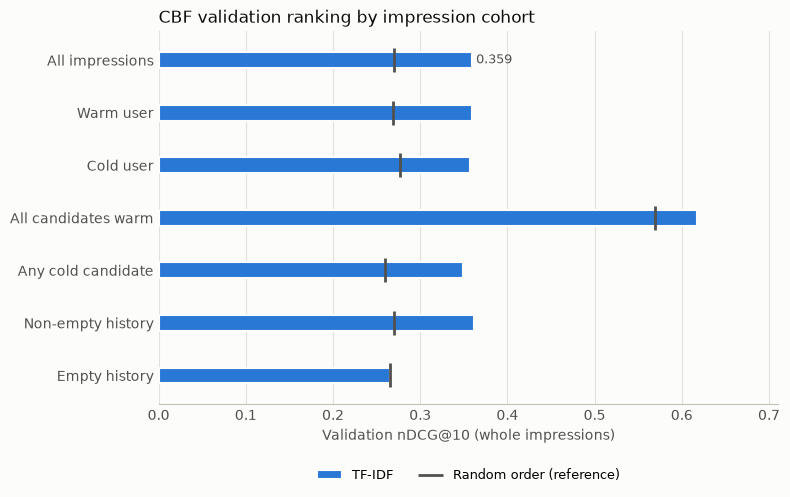

In [18]:
COHORT_LABELS = {'all': 'All impressions', 'warm_user': 'Warm user', 'cold_user': 'Cold user',
                 'all_items_warm': 'All candidates warm', 'any_cold_item': 'Any cold candidate',
                 'nonempty_history': 'Non-empty history', 'empty_history': 'Empty history'}
SERIES = {'tfidf': ('TF-IDF', '#2a78d6'), 'embedding': ('Frozen encoder', '#eb6834')}
if importlib.util.find_spec('matplotlib') is not None:
    import matplotlib.pyplot as plt
    tables = {name: pd.read_csv(RUN_DIR / f'validation_cohorts_{name}.csv').set_index('cohort')
              for name in [*SELECTED_MODELS, 'random_order']}
    shown = [c for c in COHORT_LABELS if tables['random_order'].loc[c, 'impressions'] > 0]
    models = list(SELECTED_MODELS)
    y = np.arange(len(shown))
    height = min(0.3, 0.6 / len(models))
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(shown) + 1.6), facecolor='#fcfcfb')
    ax.set_facecolor('#fcfcfb')
    for j, name in enumerate(models):
        label, color = SERIES[name]
        values = tables[name].loc[shown, 'nDCG@10'].to_numpy()
        offsets = y + (j - (len(models) - 1) / 2) * height
        ax.barh(offsets, values, height=height, color=color, edgecolor='#fcfcfb', linewidth=1.5, label=label, zorder=2)
        # Label only the headline cohort; the saved tables carry every value.
        ax.text(values[0] + 0.005, offsets[0], f'{values[0]:.3f}', va='center', fontsize=9, color='#52514e')
    span = height * len(models) / 2 + 0.08
    ax.vlines(tables['random_order'].loc[shown, 'nDCG@10'], y - span, y + span, color='#52514e', linewidth=2,
              label='Random order (reference)', zorder=3)
    ax.set_yticks(y, [COHORT_LABELS[c] for c in shown])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.15 * max(tables[name].loc[shown, 'nDCG@10'].max() for name in tables))
    ax.set_xlabel('Validation nDCG@10 (whole impressions)', color='#52514e')
    ax.set_title('CBF validation ranking by impression cohort', loc='left', color='#0b0b0b')
    ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(colors='#52514e', length=0)
    handles, labels = ax.get_legend_handles_labels()
    order = sorted(range(len(labels)), key=lambda i: labels[i].startswith('Random'))  # Models first.
    ax.legend([handles[i] for i in order], [labels[i] for i in order], frameon=False, loc='upper center',
              bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'validation_cohorts.png', dpi=160, facecolor=fig.get_facecolor(), bbox_inches='tight')
    plt.show()

## 8. Training-set metrics and validation diagnostics

Selection is locked at this point. This section reads the training click labels for the first time, only to report ranking metrics on complete training slates; they fit and select nothing. CBF has no click-trained parameters, so it cannot memorise training clicks; compare NeuMF's training and validation metrics.

The diagnostics use validation only:

- **History length.** Whole impressions grouped by supplied-history length, using the feature-based MLP notebook's buckets. Slate sizes differ between buckets, so each bucket gets its own random-order floor and the lift above it.
- **Ties.** Impressions in which every candidate gets the same score because the history is empty or shares no term with any candidate. Only the shared tie order ranks those slates.
- **Repeated terms.** The share of article–term entries in training text that occur more than once in an article. Sublinear tf changes only these entries.
- **int8 AUC check.** `04a_NeuMF.ipynb` casts labels to `int8`. Where pandas keeps grouped `int8` sums as `int8`, as in this environment, the AUC term `pos * (pos + 1) / 2` overflows for impressions with 11 or more clicks. The shift depends only on the labels, so it is the same for every model scored with that code. This notebook uses `int64`.

Saved files: `train_results.csv`, `validation_history_buckets.csv` and `validation_diagnostics.json`.

In [21]:
from sklearn.feature_extraction.text import CountVectorizer

HISTORY_BUCKETS = [('history_0', 0, 0), ('history_1_9', 1, 9), ('history_10_29', 10, 29),
                   ('history_30_49', 30, 49), ('history_50_plus', 50, np.inf)]

def history_report(part, scores):
    # Whole impressions by supplied-history length; each bucket gets its own random-order floor.
    model = ranking_metrics(part, scores, per_impression=True)
    floor = ranking_metrics(part, np.zeros(len(part['y']), dtype='float32'), per_impression=True)
    length = part['history_length'][model.index.to_numpy()]
    rows = []
    for name, low, high in HISTORY_BUCKETS:
        mask = (length >= low) & (length <= high)
        rows.append({'bucket': name, 'impressions': int(mask.sum()),
                     **{k: float(model.loc[mask, k].mean()) for k in METRICS},
                     'random_order_nDCG@10': float(floor.loc[mask, 'nDCG@10'].mean())})
    table = pd.DataFrame(rows)
    table['lift_nDCG@10'] = table['nDCG@10'] - table['random_order_nDCG@10']
    return table

def tie_report(part, scores):
    # Cosine scores are non-negative here, so a slate whose maximum is 0 scores 0 everywhere.
    grouped = pd.Series(scores).groupby(part['event_row'])
    high, low = grouped.max(), grouped.min()
    tied, zero = (high == low).to_numpy(), (high == 0).to_numpy()
    empty = part['history_length'][high.index.to_numpy()] == 0
    with_history = part['history_length'][part['event_row']] > 0
    return {'impressions': len(tied), 'all_tied': int(tied.sum()), 'all_tied_share': float(tied.mean()),
            'tied_empty_history': int((tied & empty).sum()), 'tied_no_shared_term': int((tied & zero & ~empty).sum()),
            'tied_nonzero': int((tied & ~zero).sum()),
            'zero_score_share_with_history': float((scores[with_history] == 0).mean())}

def repeated_term_share(vectorizer, config, news):
    # Raw term counts under the selected vocabulary; sublinear tf only rescales counts above 1.
    counter = CountVectorizer(vocabulary=vectorizer.vocabulary_, ngram_range=tuple(config['ngram_range']),
                              **{k: v for k, v in TFIDF_FIXED.items() if k != 'norm'})
    counts = counter.transform(article_text(news, config['text']).loc[~news['metadata_missing']])
    return float((counts.data > 1).mean())

def int8_auc_shift(part):
    # 04a_NeuMF.ipynb's label cast. The wrapped term depends only on the labels, not on the scores.
    labels = pd.Series(part['y'].astype('int8')).groupby(part['event_row'])
    n, pos = labels.size(), labels.sum()
    valid = (pos > 0) & (pos < n)
    exact = pos.astype('int64')
    shift = ((exact * (exact + 1) / 2 - pos * (pos + 1) / 2) / (exact * (n - exact)))[valid]
    return {'grouped_sum_dtype': str(pos.dtype), 'impressions_11plus_clicks': int((exact[valid] >= 11).sum()),
            'macro_auc_shift': float(shift.mean()), 'max_impression_shift': float(shift.max())}

# Training labels are read here for the first time, after selection_locked.json was written.
selected = SELECTED_MODELS['tfidf']
train = read_partition('train', labels=True)
train_scores = cosine_scores(train, tfidf_vectors(VECTORIZER, selected, train['news']))
rows = []
for name, part, scores in (('train', train, train_scores), ('validation', validation, VALIDATION_SCORES['tfidf'])):
    rows += [{'partition': name, 'model': 'tfidf', **ranking_metrics(part, scores)},
             {'partition': name, 'model': 'random_order',
              **ranking_metrics(part, np.zeros(len(part['y']), dtype='float32'))}]
fit_table = pd.DataFrame(rows)
fit_table.loc[fit_table['partition'].eq('train')].to_csv(RUN_DIR / 'train_results.csv', index=False)
display(fit_table.drop(columns=['excluded_impressions']).round(4))
ndcg = fit_table.set_index(['partition', 'model'])['nDCG@10']
print('nDCG@10 lift over random order:',
      {p: round(float(ndcg[(p, 'tfidf')] - ndcg[(p, 'random_order')]), 4) for p in ('train', 'validation')})

history_table = history_report(validation, VALIDATION_SCORES['tfidf'])
history_table.to_csv(RUN_DIR / 'validation_history_buckets.csv', index=False)
display(history_table.round(4))

diagnostics = {'training_labels': 'read after selection was locked, for training-set metrics only',
               'validation_ties': tie_report(validation, VALIDATION_SCORES['tfidf']),
               'repeated_term_share_train': repeated_term_share(VECTORIZER, selected, TRAIN_NEWS),
               'int8_auc_shift': {'train': int8_auc_shift(train), 'validation': int8_auc_shift(validation)}}
write_json(RUN_DIR / 'validation_diagnostics.json', diagnostics)
ties = diagnostics['validation_ties']
print(f"Validation impressions with every candidate tied: {ties['all_tied']:,} ({ties['all_tied_share']:.1%}); "
      f"{ties['tied_empty_history']:,} empty histories, {ties['tied_no_shared_term']:,} with no term shared with any candidate")
print(f"Candidates scoring 0 in impressions with a history: {ties['zero_score_share_with_history']:.1%}")
print(f"Training article-term entries occurring more than once: {diagnostics['repeated_term_share_train']:.1%}")
for name, audit in diagnostics['int8_auc_shift'].items():
    print(f"int8 AUC shift, {name}: {audit['impressions_11plus_clicks']} impressions with 11+ clicks, "
          f"macro AUC +{audit['macro_auc_shift']:.5f} (grouped sums stay {audit['grouped_sum_dtype']})")
del train, train_scores

,partition,model,impressions,AUC,MRR,nDCG@5,nDCG@10
0,train,tfidf,95071,0.5856,0.3035,0.3272,0.3821
1,train,random_order,95071,0.5000,0.2426,0.2525,0.3082
2,validation,tfidf,61894,0.5958,0.2856,0.3022,0.3591
3,validation,random_order,61894,0.5000,0.2109,0.2119,0.2703


nDCG@10 lift over random order: {'train': 0.0739, 'validation': 0.0888}


,bucket,impressions,AUC,MRR,nDCG@5,nDCG@10,random_order_nDCG@10,lift_nDCG@10
0,history_0,1503,0.5000,0.2060,0.2084,0.2648,0.2648,0.0000
1,history_1_9,16565,0.5604,0.2950,0.3071,0.3617,0.3031,0.0587
2,history_10_29,21063,0.6048,0.2958,0.3100,0.3671,0.2689,0.0982
3,history_30_49,10097,0.6170,0.2830,0.3031,0.3597,0.2531,0.1066
4,history_50_plus,12666,0.6214,0.2677,0.2930,0.3528,0.2441,0.1086


Validation impressions with every candidate tied: 2,238 (3.6%); 1,503 empty histories, 735 with no term shared with any candidate
Candidates scoring 0 in impressions with a history: 21.9%
Training article-term entries occurring more than once: 16.6%
int8 AUC shift, train: 131 impressions with 11+ clicks, macro AUC +0.00017 (grouped sums stay int8)
int8 AUC shift, validation: 112 impressions with 11+ clicks, macro AUC +0.00020 (grouped sums stay int8)


## 9. Final held-out evaluation

Keep `EVALUATE_TEST=False` while deciding text choices and whether to include the frozen-encoder comparison. Once the complete comparison is fixed, set it to `True` in a small cell immediately before this cell. This evaluates only the locked, validation-selected configurations: the saved training-fitted vectorizer transforms the test articles, and the pinned encoder revision embeds them. Nothing is refitted on validation or test, and test results do not select a winner.

Cold cohorts use the same train-only vocabularies as validation and NeuMF. Cohort metrics retain **whole impressions**; they do not remove cold candidates and thereby shrink the ranking pool. A completion marker prevents accidental repeated test evaluation within this run.

In [20]:
# Set EVALUATE_TEST = True here only after fixing text choices, encoders and the final comparison.
EVALUATE_TEST = True
if not EVALUATE_TEST:
    print('Test evaluation skipped. Keep test outcomes held out during development.')
else:
    require(COMPLETE_HANDOFF, 'Test evaluation requires the complete train/validation/test handoff.')
    require(not (RUN_DIR / 'test_evaluation_complete.json').exists(),
            'This run already evaluated test. Reuse its saved metrics rather than selecting settings on test.')
    locked = json.loads((RUN_DIR / 'selection_locked.json').read_text())
    require(locked['models'] == json.loads(json.dumps(SELECTED_MODELS)), 'Selected models differ from the locked settings')
    require(sha256_file(RUN_DIR / 'tfidf_vectorizer.pkl') == locked['models']['tfidf']['vectorizer_sha256'],
            'The saved vectorizer changed after selection')
    with (RUN_DIR / 'tfidf_vectorizer.pkl').open('rb') as stream:
        locked_vectorizer = pickle.load(stream)
    test = read_partition('test')
    require(validation['events']['timestamp'].max() < test['events']['timestamp'].min(), 'Validation/test chronology overlaps')
    require(not set(test['events']['event_key']) & (TRAIN_EVENT_KEYS | set(validation['events']['event_key'])),
            'Test event keys overlap earlier partitions')
    attach_cohorts(test, TRAIN_USERS, TRAIN_ARTICLES)
    # Locked transforms only: the training-fitted vectorizer and the pinned frozen encoder.
    test_scores = {'tfidf': cosine_scores(test, tfidf_vectors(locked_vectorizer, SELECTED_MODELS['tfidf'], test['news']))}
    if 'embedding' in SELECTED_MODELS:
        require(load_encoder()['revision'] == SELECTED_MODELS['embedding']['revision'], 'Encoder revision changed')
        test_scores['embedding'] = cosine_scores(test, embedding_vectors(test['news'], SELECTED_MODELS['embedding']['text']))
    test_scores['random_order'] = np.zeros(len(test['y']), dtype='float32')
    records = []
    for name, scores in test_scores.items():
        metrics = ranking_metrics(test, scores)
        records.append({'model': name, **metrics, **test['exposure_shares'],
                        'empty_history_impressions': int(test['cohorts']['empty_history'].sum())})
        cohort_report(test, scores).to_csv(RUN_DIR / f'test_cohorts_{name}.csv', index=False)
        if SAVE_PREDICTIONS and name in SELECTED_MODELS:
            test['candidates'].assign(ranking_score=scores).to_csv(
                RUN_DIR / f'test_predictions_{name}.csv.gz', index=False, compression='gzip')
    pd.DataFrame(records).to_csv(RUN_DIR / 'test_results.csv', index=False)
    write_json(RUN_DIR / 'test_evaluation_complete.json', {'models': list(SELECTED_MODELS),
        'input_sha256': INPUT_HASHES, 'metrics': records, 'timestamp_utc': datetime.now(timezone.utc).isoformat()})
    display(pd.DataFrame(records))
    print('Final test results saved. Do not revise text choices or encoders in response to these results.')

,model,impressions,excluded_impressions,AUC,MRR,nDCG@5,nDCG@10,cold_user_exposure_share,cold_item_exposure_share,empty_history_impressions
0,tfidf,73152,0,0.576274,0.276183,0.294902,0.356946,0.897433,0.8979,2214
1,random_order,73152,0,0.500000,0.218181,0.222862,0.286491,0.897433,0.8979,2214


Final test results saved. Do not revise text choices or encoders in response to these results.


**Final test result** (the number used in the report): TF-IDF CBF on all 73,152 test impressions scores AUC 0.5763, MRR 0.2762, nDCG@5 0.2949 and **nDCG@10 0.3569**. A random order scores nDCG@10 0.2865.

## 10. Test diagnostics of the locked model

A post-hoc look at the Section 9 test scores: history-length buckets, ties and the int8 AUC check, defined as in Section 8. The cell reads no new data and changes nothing; the configuration stays as selected on validation.

Saved files: `test_history_buckets.csv` and `test_diagnostics.json`.

In [22]:
# Uses the locked test scores from Section 9; nothing is refitted or reselected.
if 'test_scores' not in globals():
    print('Test diagnostics skipped: run the final held-out evaluation in Section 9 first.')
else:
    history_test = history_report(test, test_scores['tfidf'])
    history_test.to_csv(RUN_DIR / 'test_history_buckets.csv', index=False)
    display(history_test.round(4))
    test_diagnostics = {'test_ties': tie_report(test, test_scores['tfidf']), 'int8_auc_shift': int8_auc_shift(test)}
    write_json(RUN_DIR / 'test_diagnostics.json', test_diagnostics)
    ties, audit = test_diagnostics['test_ties'], test_diagnostics['int8_auc_shift']
    print(f"Test impressions with every candidate tied: {ties['all_tied']:,} ({ties['all_tied_share']:.1%}); "
          f"{ties['tied_empty_history']:,} empty histories, {ties['tied_no_shared_term']:,} with no shared term")
    print(f"int8 AUC shift, test: {audit['impressions_11plus_clicks']} impressions with 11+ clicks, "
          f"macro AUC +{audit['macro_auc_shift']:.5f}")
    print('These describe the locked model. Do not change settings in response to them.')

,bucket,impressions,AUC,MRR,nDCG@5,nDCG@10,random_order_nDCG@10,lift_nDCG@10
0,history_0,2214,0.5000,0.2203,0.2259,0.2917,0.2917,0.0000
1,history_1_9,20094,0.5440,0.2886,0.3031,0.3633,0.3186,0.0446
2,history_10_29,24773,0.5780,0.2785,0.2958,0.3577,0.2847,0.0730
3,history_30_49,11255,0.6018,0.2757,0.2960,0.3595,0.2696,0.0899
4,history_50_plus,14816,0.6091,0.2641,0.2918,0.3549,0.2580,0.0969


Test impressions with every candidate tied: 3,197 (4.4%); 2,214 empty histories, 983 with no shared term
int8 AUC shift, test: 88 impressions with 11+ clicks, macro AUC +0.00013
These describe the locked model. Do not change settings in response to them.


## 11. Outputs and report guidance

Keep the complete timestamped run folder together:

- `search_configs.json` and `trials_<family>.csv`: the predeclared grid and every validation trial.
- `tfidf_vectorizer.pkl` and `tfidf_vocabulary.csv`: the selected training-fitted vectorizer and its terms.
- `selected_<family>.json`, `selection_locked.json` and `selected_validation_results.csv`: selected configurations and validation evidence. The lock includes the vectorizer hash and, when used, the pinned encoder revision.
- `validation_<name>.json` and `validation_cohorts_<name>.csv`: whole-impression metrics and cohort breakdowns, including the random-order reference. Test evaluation, when explicitly enabled, writes the matching `test_cohorts_<name>.csv`, `test_results.csv` and a completion record.
- `train_results.csv`, `validation_history_buckets.csv` and `validation_diagnostics.json`: training-set metrics on complete slates and the validation diagnostics from Section 8. `test_history_buckets.csv` and `test_diagnostics.json`: the post-hoc test diagnostics from Section 10.
- `validation_cohorts.png`: the cohort chart.
- `run_manifest.json`: input hashes, libraries, protocol and settings.
- Optional full-candidate prediction files include labels for evaluation; labels are never model inputs. Predictions retain the original candidate keys and ordering.

Report this as a **content-similarity model**: the same family as the reference CBF, without the reference's learned logistic-regression combination of matching features. Its only fitted component is the training-text TF-IDF vocabulary with its IDF weights. Click labels enter only evaluation and the small validation selection.

Compare it with NeuMF on the same cohorts. CBF scores a never-seen article from its text, which matters in this chronological task: Section 2 prints the share of validation candidate exposures whose articles were never shown in training. ID-only NeuMF cannot distinguish two new articles by their IDs.

State the limitations. An empty history leaves CBF at random order. Profiles are static because MIND supplies one fixed history per user. Popularity, recency and position are not modelled. TF-IDF matches words rather than meanings; the frozen encoder addresses meaning but still ignores popularity and recency. When reporting the frozen-encoder variant, name the model and revision, and describe it as transfer from external pretraining rather than a model trained on MIND.

## References and lecture alignment

- Pazzani and Billsus, Content-Based Recommendation Systems, in *The Adaptive Web*, LNCS 4321, Springer, 2007: user profiles built from the content of previously liked items.
- Lops, de Gemmis and Semeraro, Content-based Recommender Systems: State of the Art and Trends, in *Recommender Systems Handbook*, Springer, 2011: vector-space item representations and similarity-based ranking.
- Salton and Buckley, Term-weighting approaches in automatic text retrieval, *Information Processing & Management* 24(5), 1988: TF-IDF weighting and cosine matching.
- Wu et al., MIND: A Large-scale Dataset for News Recommendation, ACL 2020: https://aclanthology.org/2020.acl-main.331/ . This notebook uses the group's chronological MIND partitions and complete-impression AUC, MRR and nDCG@5/10.
- Reimers and Gurevych, Sentence-BERT, EMNLP-IJCNLP 2019: https://arxiv.org/abs/1908.10084 , and Wang et al., MiniLM, NeurIPS 2020: https://arxiv.org/abs/2002.10957 , for the optional frozen encoder. Model card: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
- scikit-learn TfidfVectorizer: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- Provided **Lecture 2 Representation**, slide 26: fit transform parameters on training only; here, the TF-IDF vocabulary and IDF weights.
- Provided **Lecture 4 Evaluation**, slides 32–38: ranking metrics and candidate-pool sensitivity. Here the agreed task is reranking complete MIND impression slates.
- `04a_NeuMF.ipynb` in this repository: the shared metric function, tie sequence, cold-start cohorts and held-out evaluation protocol.